# Qiskit Fall Fest 2026 — Challenge 4: Quantum Correlation Switch
**IBM Quantum | Vishnu Institute of Technology**

## Aim
Design a two-qubit circuit that works like a **switch** between two behaviours:

- **Part A:** the two measured bits are *the same* (`00` and `11` dominate),
- **Part B:** the two measured bits are *opposite* (`01` and `10` dominate).

We only use gates from the workshop (`H`, `CX`, `X`), at most 4 gates, and 100 shots per experiment.

## 1. Setup
Run the install cell once if Qiskit is missing (works on Google Colab too). The experiments run on the local Aer simulator, and the last section optionally repeats them on a real IBM Quantum device.

In [ ]:
%pip install -q qiskit qiskit-aer matplotlib pylatexenc

In [2]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

SHOTS = 100
OUTCOMES = ["00", "01", "10", "11"]
sim = AerSimulator()

def with_measurement(gates):
    """Wrap a gate-only 2-qubit circuit into a 2-qubit / 2-bit circuit and measure both qubits."""
    qc = QuantumCircuit(2, 2)
    qc.compose(gates, inplace=True)
    qc.measure([0, 1], [0, 1])
    return qc

def run(qc):
    """Execute for 100 shots; always return all four outcomes (missing ones count as 0)."""
    counts = sim.run(transpile(qc, sim), shots=SHOTS).result().get_counts()
    return {k: counts.get(k, 0) for k in OUTCOMES}

def exact_counts(gates):
    """Ideal (noise-free) expected number of shots per outcome, from the circuit's quantum state."""
    p = Statevector.from_instruction(gates).probabilities_dict()
    return {k: SHOTS * float(p.get(k, 0)) for k in OUTCOMES}

def same_bits(counts):      # shots with 00 or 11
    return counts["00"] + counts["11"]

def opposite_bits(counts):  # shots with 01 or 10
    return counts["01"] + counts["10"]

print(f"Ready: {SHOTS} shots per circuit on {sim.name}")

Ready: 100 shots per circuit on aer_simulator


**How to read the results:** Qiskit writes each outcome as two bits in the order **q1 q0**. For example `01` means qubit 1 gave `0` and qubit 0 gave `1`. Because we only care whether the two bits are *equal or different*, this order does not change any conclusion.

## 2. Predictions (written before running)

| | Part A | Part B |
|---|---|---|
| Gates | H on q0, CX(q0 → q1) | H on q0, CX(q0 → q1), **X on q1** |
| Dominant outcomes | `00` and `11` (about 50 each) | `01` and `10` (about 50 each) |
| Why | H puts q0 in superposition and CX copies it to q1, so the bits always match | the extra X flips q1, so the bits always differ |

**Will all four outcomes appear?** No. In both circuits only *two* of the four outcomes are possible. The other two should be missing (ideally 0 shots, or at most a few on a noisy real device).
**Why are some outcomes much more frequent than others?** The two qubits are **entangled**: their results are linked, so the outcomes that break the link are not allowed, and the allowed two share the shots roughly equally.

## 3. Part A — Correlated outcomes (`00` and `11`)

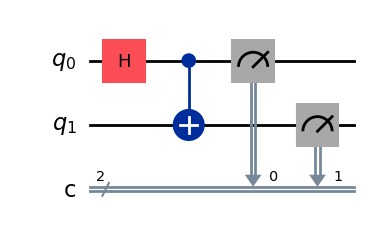

In [3]:
gates_a = QuantumCircuit(2)
gates_a.h(0)
gates_a.cx(0, 1)

qc_a = with_measurement(gates_a)
qc_a.draw("mpl")

Part A counts: {'00': 54, '01': 0, '10': 0, '11': 46}
Same bits (00 or 11): 100 / 100


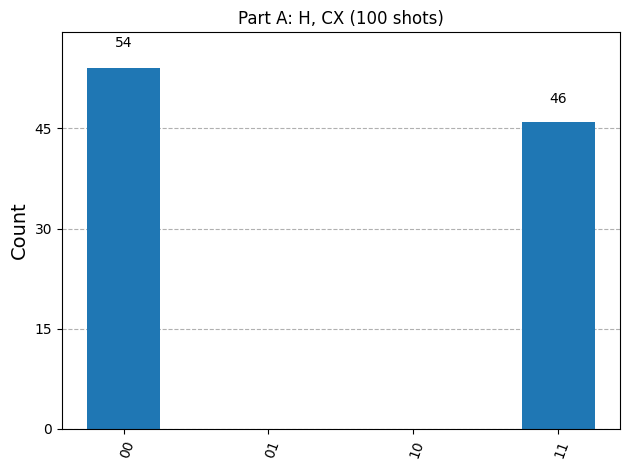

In [4]:
counts_a = run(qc_a)
print("Part A counts:", counts_a)
print(f"Same bits (00 or 11): {same_bits(counts_a)} / {SHOTS}")
plot_histogram(counts_a, title="Part A: H, CX (100 shots)")

## 4. Part B — Opposite outcomes (`01` and `10`)
We keep the Part A circuit and add **one X gate on qubit 1** at the end. It has 3 gates before measurement (limit: 4).

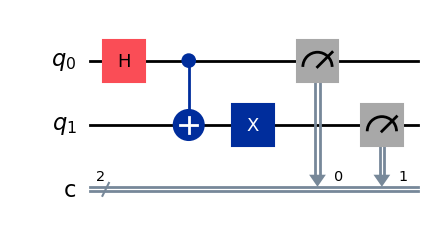

In [5]:
gates_b = QuantumCircuit(2)
gates_b.h(0)
gates_b.cx(0, 1)
gates_b.x(1)           # <- the switch: flips qubit 1

qc_b = with_measurement(gates_b)
qc_b.draw("mpl")

Part B counts: {'00': 0, '01': 46, '10': 54, '11': 0}
Opposite bits (01 or 10): 100 / 100


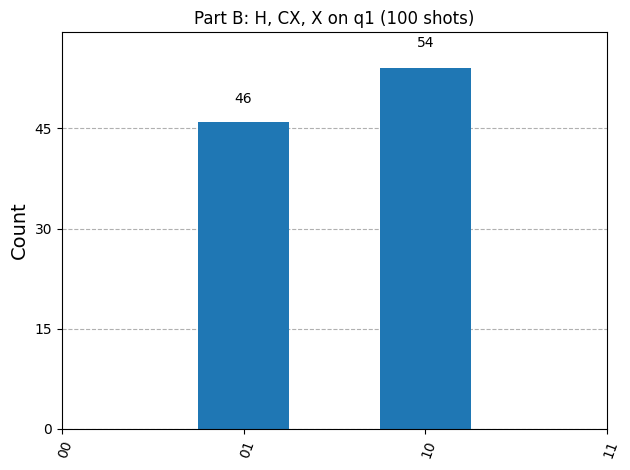

In [6]:
counts_b = run(qc_b)
print("Part B counts:", counts_b)
print(f"Opposite bits (01 or 10): {opposite_bits(counts_b)} / {SHOTS}")
plot_histogram(counts_b, title="Part B: H, CX, X on q1 (100 shots)")

## 5. Part C — Comparing the two experiments

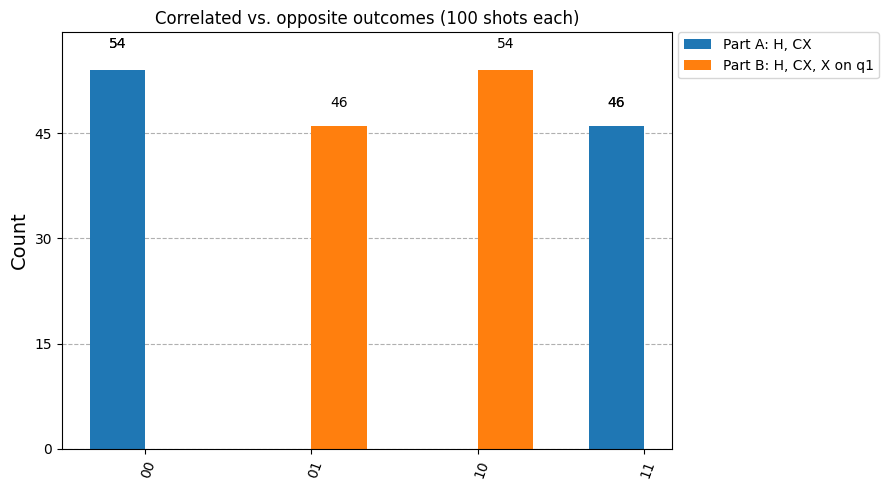

In [7]:
plot_histogram([counts_a, counts_b],
               legend=["Part A: H, CX", "Part B: H, CX, X on q1"],
               title="Correlated vs. opposite outcomes (100 shots each)", figsize=(9, 5))

In [8]:
print(f"{'Experiment':<26}{'00':>5}{'01':>5}{'10':>5}{'11':>5}   {'Same bits':<11}{'Opposite bits'}")
print("-" * 68)
for name, cnt in [("Part A: H, CX", counts_a), ("Part B: H, CX, X on q1", counts_b)]:
    print(f"{name:<26}{cnt['00']:>5}{cnt['01']:>5}{cnt['10']:>5}{cnt['11']:>5}   "
          f"{same_bits(cnt):<11}{opposite_bits(cnt)}")

Experiment                   00   01   10   11   Same bits  Opposite bits
--------------------------------------------------------------------
Part A: H, CX                54    0    0   46   100        0
Part B: H, CX, X on q1        0   46   54    0   0          100


### Answers to the comparison questions

- **Which outcomes dominate in Part A?** `00` and `11`, about half of the shots each. The bits always match.
- **Which outcomes dominate in Part B?** `01` and `10`, about half of the shots each. The bits always differ.
- **What changed between the two circuits?** Only one extra gate: an `X` on qubit 1, applied after the `CX`.
- **Why did the relationship change?** Part A makes the entangled state (|00⟩ + |11⟩)/√2. The `X` gate flips qubit 1 in *every* branch of that state, turning it into (|01⟩ + |10⟩)/√2. The qubits are still perfectly linked, but the link changed from "equal" to "opposite".

## 6. The correlation switch in one function
The whole design fits in one small function with a single on/off setting. We also check the design constraints (2 qubits, at most 4 gates, only workshop gates) and show that putting the `X` at the *start* instead of the end gives the same Part B behaviour.

In [9]:
def correlation_circuit(opposite):
    """opposite=False -> bits match (00, 11).   opposite=True -> bits differ (01, 10)."""
    g = QuantumCircuit(2)
    g.h(0)
    g.cx(0, 1)
    if opposite:
        g.x(1)          # the switch
    return g

WORKSHOP_GATES = {"h", "cx", "x"}
for label, opposite in [("switch OFF (Part A)", False), ("switch ON  (Part B)", True)]:
    g = correlation_circuit(opposite)
    ops = dict(g.count_ops())
    n_gates = sum(ops.values())
    cnt = run(with_measurement(g))
    ok = g.num_qubits == 2 and n_gates <= 4 and set(ops) <= WORKSHOP_GATES
    print(f"{label}: gates={ops}, total={n_gates}, constraints met: {ok}, counts={cnt}")

# Alternative design: apply X to qubit 1 BEFORE the Bell circuit instead
alt = QuantumCircuit(2)
alt.x(1); alt.h(0); alt.cx(0, 1)
print("\nX placed at the start instead:", run(with_measurement(alt)))

switch OFF (Part A): gates={'h': 1, 'cx': 1}, total=2, constraints met: True, counts={'00': 56, '01': 0, '10': 0, '11': 44}


switch ON  (Part B): gates={'h': 1, 'cx': 1, 'x': 1}, total=3, constraints met: True, counts={'00': 0, '01': 49, '10': 51, '11': 0}



X placed at the start instead: {'00': 0, '01': 55, '10': 45, '11': 0}


## 7. Prediction vs. actual
For every outcome we compare the measured count with the ideal expected count. A result passes when it is within 3 standard deviations (the normal random spread of 100 shots). Outcomes that should never happen must be exactly 0.

In [10]:
checks = {"Part A: H, CX": (gates_a, counts_a),
          "Part B: H, CX, X on q1": (gates_b, counts_b),
          "X placed first": (alt, run(with_measurement(alt)))}

print(f"{'Circuit':<26}{'Expected 00/01/10/11':<24}{'Measured':<18}Pass?")
print("-" * 74)
for name, (gates, meas) in checks.items():
    exp = exact_counts(gates)
    ok = True
    for k in OUTCOMES:
        p = exp[k] / SHOTS
        sigma = (SHOTS * p * (1 - p)) ** 0.5
        ok &= abs(meas[k] - exp[k]) <= 3 * sigma + 1e-9
    e = "/".join(f"{exp[k]:.0f}" for k in OUTCOMES)
    m = "/".join(str(meas[k]) for k in OUTCOMES)
    print(f"{name:<26}{e:<24}{m:<18}{'Yes' if ok else 'No'}")

Circuit                   Expected 00/01/10/11    Measured          Pass?
--------------------------------------------------------------------------
Part A: H, CX             50/0/0/50               54/0/0/46         Yes
Part B: H, CX, X on q1    0/50/50/0               0/46/54/0         Yes
X placed first            0/50/50/0               0/54/46/0         Yes


## 8. How the circuit produces the different correlations

1. `H` on qubit 0 puts it in an equal superposition of |0⟩ and |1⟩.
2. `CX` (controlled-NOT) makes qubit 1 follow qubit 0, creating the **entangled** Bell state (|00⟩ + |11⟩)/√2. Measuring either qubit gives a random bit, but the second qubit's bit is always equal to the first. That is Part A.
3. Adding `X` on qubit 1 flips its bit in both branches, so the state becomes (|01⟩ + |10⟩)/√2. The first bit is still random, but the second is now always the opposite. That is Part B.

So the single `X` gate acts as the **switch**: without it the qubits agree, with it they disagree. The counts are close to 50/50 inside each pair, not exactly equal, because 100 random shots always fluctuate a little.

**Checklist:** 2 qubits ✔  both measured ✔  at most 4 gates ✔  workshop gates only (H, CX, X) ✔  predictions first ✔  100 shots each ✔  histograms and comparison ✔  explanation ✔

## 9. (Optional) Run Part A and Part B on a real IBM Quantum device

You need an IBM Cloud API key from https://quantum.cloud.ibm.com. Real devices have noise, so a few shots may land on the "wrong" outcomes. That is why the challenge says the results are *predominantly* `00`/`11` or `01`/`10`.

**Step 1 (once):** paste your key into the cell below and run it. **Step 2:** delete the key from the cell afterwards so it never ends up in a file you share or upload. If no credentials are saved, the next cell skips the hardware run, so "Run All" still works.

In [11]:
# %pip install -q qiskit-ibm-runtime
from qiskit_ibm_runtime import QiskitRuntimeService

IBM_API_KEY  = "PASTE_YOUR_API_KEY_HERE"   # delete after saving
IBM_INSTANCE = ""                          # optional: instance name or CRN

if IBM_API_KEY != "PASTE_YOUR_API_KEY_HERE":
    opts = dict(channel="ibm_quantum_platform", token=IBM_API_KEY,
                overwrite=True, set_as_default=True)
    if IBM_INSTANCE:
        opts["instance"] = IBM_INSTANCE
    QiskitRuntimeService.save_account(**opts)
    print("Credentials saved. Delete your key from this cell now.")
else:
    print("No new key entered; using saved credentials if available.")

No new key entered; using saved credentials if available.


In [12]:
from qiskit_ibm_runtime import SamplerV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

try:
    service = QiskitRuntimeService()
    hw = service.least_busy(operational=True, simulator=False, min_num_qubits=2)
except Exception as err:
    hw = None
    print("Skipping the hardware run (no usable IBM credentials):", err)

if hw is not None:
    print("Running on:", hw.name)
    hw_labels = ["Part A: H, CX", "Part B: H, CX, X on q1"]
    pm = generate_preset_pass_manager(backend=hw, optimization_level=0)   # keep gates as written
    job = SamplerV2(mode=hw).run([pm.run(q) for q in (qc_a, qc_b)], shots=SHOTS)
    print("Job ID:", job.job_id(), "- waiting for the result ...")
    hw_counts = [p.data.c.get_counts() for p in job.result()]   # register is named 'c' by default
    for label, cnt in zip(hw_labels, hw_counts):
        print(f"{label}: {dict(sorted(cnt.items()))}")
    display(plot_histogram(hw_counts, legend=hw_labels,
                           title=f"IBM hardware ({hw.name}), 100 shots", figsize=(9, 5)))
    # Qiskit rewrites our gates into the device's native gates, so more physical gates run than the 3 we wrote.

Skipping the hardware run (no usable IBM credentials): "Unable to find account. Please make sure an account with the channel name 'ibm_quantum_platform' is saved."
